In [1]:
!pip install "opencv-python==4.10.0.84"
!pip install cvlib
import cvlib
from cvlib.object_detection import draw_bbox, YOLO

/usr/local/lib/python3.13/dist-packages/cvlib/face_detection.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename, Requirement


In [2]:
# Download the YOLOv3 model configuration, weights and labels files
# !wget https://github.com/yongminli/data/raw/main/yolov3-tiny.cfg -O yolov3-tiny.cfg
# !wget https://github.com/yongminli/data/raw/main/yolov3-tiny.weights -O yolov3-tiny.weights
# !wget https://github.com/yongminli/data/raw/main/yolov3.txt -O yolov3.txt

# !wget http://www.brunel.ac.uk/~csstyyl/tmp/yolov3.cfg -O yolov3.cfg
# !wget http://www.brunel.ac.uk/~csstyyl/tmp/yolov3.weights -O yolov3.weights
# !wget http://www.brunel.ac.uk/~csstyyl/tmp/yolov3.txt -O yolov3.txt
# path = ""

# Alternatively you can save the data to your Google Drive, and load the data from there
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/My Drive/data/"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# The default YOLO model files
config = path + 'yolov3.cfg'
weights = path + 'yolov3.weights'
labels = path + 'yolov3.txt'

# # Alternative the "tiny" version of YOLO, which is faster but less accurate
# config = path + 'yolov3-tiny.cfg'
# weights = path + 'yolov3-tiny.weights'
# labels = path + 'yolov3.txt'

# Construct the YOLOv3 Model
yolo = YOLO(weights, config, labels)


[INFO] Initializing YOLO ..


In [4]:
# # Load the image files to Google Colab
# from google.colab import files
# file = files.upload()

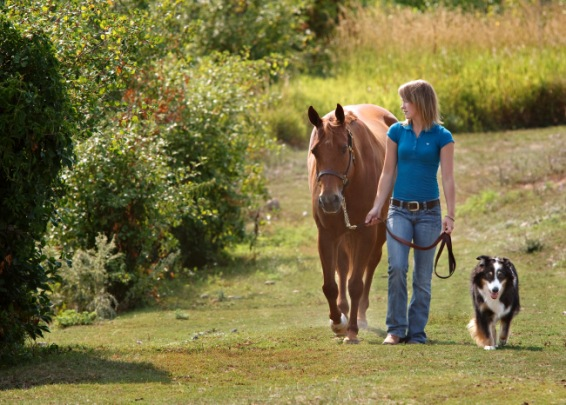

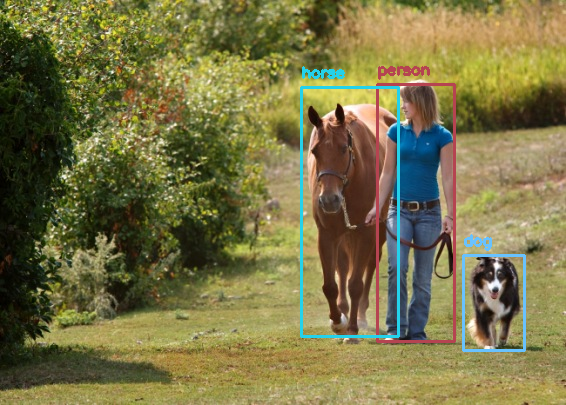

In [5]:
import cv2
from google.colab.patches import cv2_imshow

# Read an image file
img = cv2.imread(path+'objects.jpg')
# img = cv2.imread(path+'objects2.jpg')
cv2_imshow(img)
print()

# Detect objects from the image, and display the results
bbox, label, conf = yolo.detect_objects(img)
# bbox, label, conf = yolo.detect_objects(img, confidence=0.25, nms_thresh=0.2)
yolo.draw_bbox(img, bbox, label, conf)
cv2_imshow(img)